In [3]:
%pip install ripser umap-learn kmapper persim PersistenceImages
%pip install gudhi
%pip install opencv-python
%pip install pydicom
%pip install networkx

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# import networkx as nx
# import pydicom
from pathlib import Path
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
import importlib

import Algorithms.image_pd_v01 as image_pd
import Algorithms.os_tool_v01 as os_tool
import Algorithms.pd_feat_tool_v01 as pd_feat_tool
import Algorithms.pickle_tool_v01 as pickle_tool

from Algorithms import image_search_tool 
from Algorithms import region_mask_tool

In [2]:
#功能：設置根目錄

if 'PROJECT_ROOT' not in globals():
    PROJECT_ROOT = Path.cwd()   # 第一次執行時，記錄當下位置（即 main.ipynb 所在資料夾）

os.chdir(PROJECT_ROOT)
project_path = PROJECT_ROOT

print(f"專案根目錄已鎖定為: {project_path}")

專案根目錄已鎖定為: c:\Users\tntki\OneDrive\Desktop\Eda Hosp


兩者怎麼搭配
現象	建議調整
範圍破碎、有很多小洞或鋸齒	調大 Blur，必要時也調大 Tolerance
範圍太小，沒填滿目標	調大 Tolerance
範圍溢出到旁邊不該選的區域	調小 Tolerance，或調小 Blur

建議先把 Blur 固定在 2 左右，再用 Tolerance 從 10 到 20 開始上下調整，通常這樣最快找到合適的設定。

In [12]:
#設置資料夾topic
file_location = r"c:\Users\tntki\OneDrive\Desktop\Eda Hosp\Healthy Pancreas"
image_size = 200

In [14]:
importlib.reload(region_mask_tool)
#(資料夾位置, 方形大小, 是否保留裁切外範圍)
region_mask_tool.run(file_location , image_size, use_tolerance=False, use_blur=False)
normalized_file_location = f"normalized_{file_location}_{image_size}x{image_size}"

找到 240 張圖片，正方形邊長 n=200。單擊放置正方形，拖曳可調整大小；n/p 換圖；全部選完按 s 一次輸出；q 離開
已輸出 1 張圖片到: c:\Users\tntki\OneDrive\Desktop\Eda Hosp\normalized_Healthy Pancreas_200x200_2


收集資料夾內的圖片為cv2
images = image_search_tool.search_images(project_path, PATH_LEVELS, RECURSIVE)

依序展示圖片
image_search_tool.show_images_grid(images, cols=6)

目標資料夾: c:\Users\tntki\OneDrive\Desktop\Eda Hosp\normalized_Pancreatitis 1 522931_200x200
在 'c:\Users\tntki\OneDrive\Desktop\Eda Hosp\normalized_Pancreatitis 1 522931_200x200' 中找到 196 張圖片。


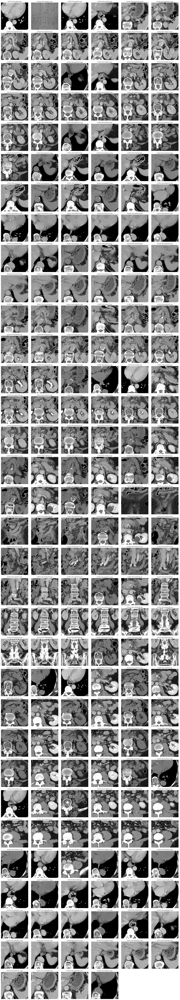

In [ ]:
PATH_LEVELS = [normalized_file_location]
RECURSIVE = False   #是否一同收集子資料夾的圖片

images = image_search_tool.search_images(project_path, PATH_LEVELS, RECURSIVE)   # 收集並轉為 cv2 格式
#image_search_tool.show_images_grid(images, cols=6)                               # 展示所有圖片